# 01. EDA и подготовка данных — SMS Spam Detection

**Цель ноутбука:** понять структуру датасета SMS Spam Collection, проверить качество данных
(пропуски, дубликаты, баланс классов), найти признаки, отличающие спам, и обосновать
решения по предобработке и разбиению выборки.

Перед запуском: `pip install -r requirements.txt`. Ноутбук запускается из папки `notebooks/`.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))  # чтобы импортировать src/

import re
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer

from src.config import FIGURES_DIR
from src.data import download_raw, load_raw, clean, deduplicate, split

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_colwidth", 120)

## 1. Загрузка исходных данных

In [2]:
download_raw()
raw = load_raw()
print("Размер:", raw.shape)
raw.head(10)

Файл уже есть: /Users/alanamukanova/Downloads/sms-spam-detection/data/raw/SMSSpamCollection
Размер: (5574, 2)


,label,text
0,ham,"Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std t...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives around here though"
5,spam,FreeMsg Hey there darling it's been 3 week's now and no word back! I'd like some fun you up for it still? Tb ok! XxX...
6,ham,Even my brother is not like to speak with me. They treat me like aids patent.
7,ham,As per your request 'Melle Melle (Oru Minnaminunginte Nurungu Vettam)' has been set as your callertune for all Calle...
8,spam,WINNER!! As a valued network customer you have been selected to receivea £900 prize reward! To claim call 0906170146...
9,spam,Had your mobile 11 months or more? U R entitled to Update to the latest colour mobiles with camera for Free! Call Th...


## 2. Очистка, пропуски и дубликаты

Дубликаты удаляем **до** разбиения на train/val/test — иначе одинаковые сообщения окажутся
в разных выборках и метрики будут завышены (data leakage).

In [3]:
print("Пропуски по столбцам:\n", raw.isna().sum(), sep="")
df = clean(raw)
print("После очистки:", len(df))

dup_mask = df["text"].str.lower().str.split().str.join(" ").duplicated(keep=False)
print("Сообщений, имеющих копии:", int(dup_mask.sum()))
display(df[dup_mask].groupby("text").size().sort_values(ascending=False).head(10).rename("копий"))

df, dedup_stats = deduplicate(df)
dedup_stats, len(df)

Пропуски по столбцам:
label    0
text     0
dtype: int64
После очистки: 5574
Сообщений, имеющих копии: 705


text
Sorry, I'll call later                                                                                                                                                                 30
I cant pick the phone right now. Pls send a message                                                                                                                                    12
Ok...                                                                                                                                                                                  10
Wen ur lovable bcums angry wid u, dnt take it seriously.. Coz being angry is d most childish n true way of showing deep affection, care n luv!.. kettoda manda... Have nice day da.     4
Your opinion about me? 1. Over 2. Jada 3. Kusruthi 4. Lovable 5. Silent 6. Spl character 7. Not matured 8. Stylish 9. Simple Pls reply..                                                4
Ok.                                                              

({'rows_before_dedup': 5574,
  'duplicates_removed': 415,
  'texts_with_conflicting_labels': 0},
 5159)

## 3. Баланс классов

,count,share
label,,
ham,4517,0.876
spam,642,0.124


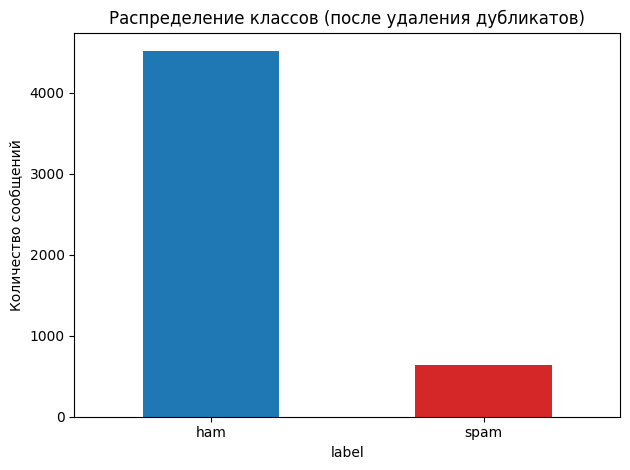

In [4]:
counts = df["label"].value_counts()
display(pd.DataFrame({"count": counts, "share": (counts / counts.sum()).round(3)}))

ax = counts.plot.bar(color=["tab:blue", "tab:red"], rot=0, title="Распределение классов (после удаления дубликатов)")
ax.set_ylabel("Количество сообщений")
plt.tight_layout(); plt.savefig(FIGURES_DIR / "eda_class_balance.png", dpi=150); plt.show()

Классы несбалансированы, поэтому **accuracy — плохая основная метрика**: модель, которая
всегда отвечает «ham», уже получит высокую accuracy. Основные метрики: precision, recall и F1
для класса spam, а также PR-AUC.

## 4. Длина сообщений

n_chars                                                n_words        \
        count   mean   std   min    25%    50%    75%    max   count  mean   
label                                                                        
ham    4517.0   70.9  56.6   2.0   34.0   53.0   91.0  910.0  4517.0  14.2   
spam    642.0  137.4  30.0  13.0  131.0  148.0  157.0  223.0   642.0  23.7   

                                           
        std  min   25%   50%   75%    max  
label                                      
ham    11.2  1.0   7.0  11.0  19.0  171.0  
spam    6.0  2.0  21.2  25.0  28.0   35.0

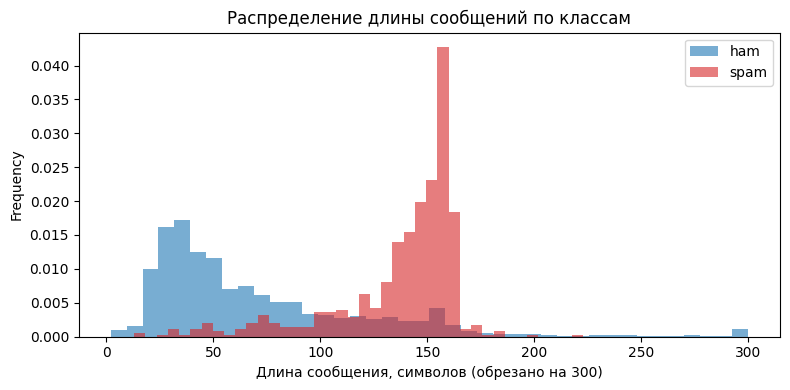

In [5]:
df["n_chars"] = df["text"].str.len()
df["n_words"] = df["text"].str.split().str.len()
display(df.groupby("label")[["n_chars", "n_words"]].describe().round(1))

fig, ax = plt.subplots(figsize=(8, 4))
for label, color in (("ham", "tab:blue"), ("spam", "tab:red")):
    df.loc[df["label"] == label, "n_chars"].clip(upper=300).plot.hist(
        bins=40, alpha=0.6, color=color, label=label, ax=ax, density=True)
ax.set_xlabel("Длина сообщения, символов (обрезано на 300)"); ax.legend()
ax.set_title("Распределение длины сообщений по классам")
plt.tight_layout(); plt.savefig(FIGURES_DIR / "eda_length_hist.png", dpi=150); plt.show()

## 5. Простые признаки, характерные для спама

In [6]:
feats = pd.DataFrame({
    "label": df["label"],
    "has_digits_5plus": df["text"].str.contains(r"\d{5,}"),       # номера телефонов, короткие номера
    "has_url": df["text"].str.contains(r"http|www\.|\.com", case=False),
    "has_currency": df["text"].str.contains(r"[£$€]|\bprize\b|\bcash\b", case=False),
    "has_exclamation": df["text"].str.contains("!"),
    "upper_ratio": df["text"].map(lambda t: sum(c.isupper() for c in t) / max(len(t), 1)),
})
feats.groupby("label").mean().round(3).T

label,ham,spam
has_digits_5plus,0.001,0.765
has_url,0.003,0.160
has_currency,0.007,0.364
has_exclamation,0.117,0.470
upper_ratio,0.057,0.110


Эти наблюдения объясняют, почему мы **не удаляем** цифры, ссылки и символы валют при
предобработке: они несут сильный сигнал. В финальной части планируем проверить замену
их на специальные токены (`<PHONE>`, `<URL>`, `<MONEY>`).

## 6. Самые частые слова в каждом классе

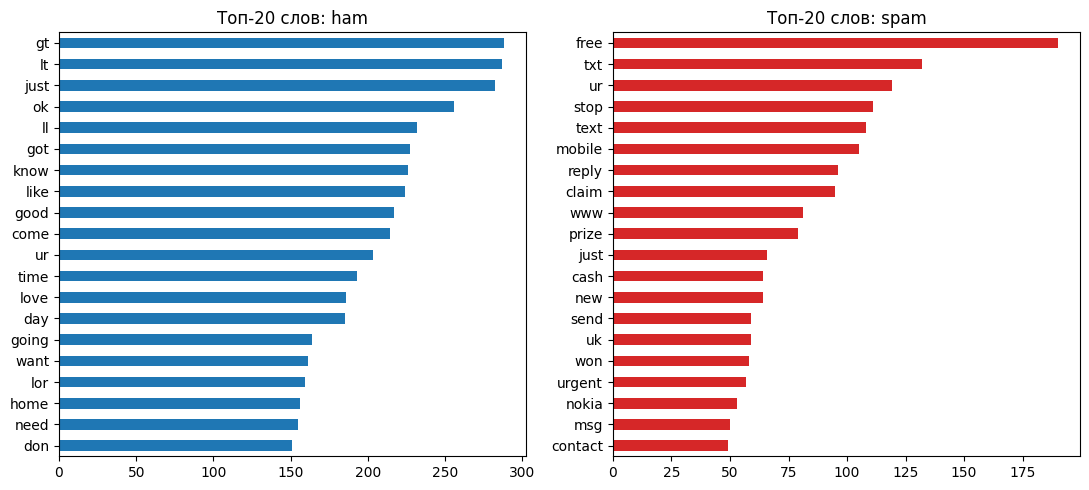

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for ax, label, color in zip(axes, ("ham", "spam"), ("tab:blue", "tab:red")):
    cv = CountVectorizer(stop_words="english", token_pattern=r"(?u)\b[a-zA-Z]{2,}\b")
    X = cv.fit_transform(df.loc[df["label"] == label, "text"])
    top = pd.Series(X.sum(axis=0).A1, index=cv.get_feature_names_out()).nlargest(20)
    top.sort_values().plot.barh(ax=ax, color=color, title=f"Топ-20 слов: {label}")
plt.tight_layout(); plt.savefig(FIGURES_DIR / "eda_top_words.png", dpi=150); plt.show()

## 7. Разбиение на train / validation / test

Стратифицированное разбиение 70/15/15 с фиксированным `random_state=42`
(та же функция, что в `src/data.py`). **Test-выборка не используется до финальной защиты.**

In [8]:
train, val, test = split(df)
pd.DataFrame({
    "size": [len(train), len(val), len(test)],
    "spam_share": [train["y"].mean(), val["y"].mean(), test["y"].mean()],
}, index=["train", "val", "test"]).round(3)

,size,spam_share
train,3611,0.125
val,774,0.124
test,774,0.124


In [9]:
# Проверка на утечку: ни одно сообщение не должно встречаться в двух выборках
norm = lambda s: set(s.str.lower().str.split().str.join(" "))
print("train ∩ val :", len(norm(train["text"]) & norm(val["text"])))
print("train ∩ test:", len(norm(train["text"]) & norm(test["text"])))
print("val ∩ test  :", len(norm(val["text"]) & norm(test["text"])))

train ∩ val : 0
train ∩ test: 0
val ∩ test  : 0


## 8. Выводы по EDA

- **Размер:** 5 574 сообщения, пропусков нет. Удалено 415 дубликатов (705 сообщений имели копии) → 5 159.
  Самые частые дубликаты — шаблонные короткие ответы ("Sorry, I'll call later" — 30 раз).
- **Дисбаланс:** 87,6% ham / 12,4% spam → основные метрики: precision, recall, F1 для spam и PR-AUC.
- **Длина:** спам в среднем вдвое длиннее (137 vs 71 символ, медиана 148 vs 53).
  Спам сконцентрирован около 130–160 символов — спамеры заполняют SMS почти до лимита в 160 символов.
- **Сильные признаки спама:**
  числа из 5+ цифр — 76,5% спама vs 0,1% ham; деньги/приз — 36,4% vs 0,7%;
  ссылки — 16% vs 0,3%; «!» — 47% vs 11,7%. Поэтому цифры и ссылки не удаляем.
- **Частые слова спама:** free, txt, stop, mobile, reply, claim, prize, cash, won, urgent.
- **Артефакт данных:** в ham среди топ-слов «gt» и «lt» — это HTML-сущности `&lt;` `&gt;`,
  которыми в датасете заменены анонимизированные фрагменты. Модель может выучить ложную закономерность →
  в финальной части декодируем HTML-сущности.
- **Разбиение:** 3 611 / 774 / 774, доля спама одинакова (≈12,4%), пересечений между выборками нет — утечки данных нет.
- **Ограничения:** только английский язык, данные ~2011 года, британская специфика (£, короткие номера).